In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn import model_selection 
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
photo_df_OK=pd.read_csv(f'14112025cam2_2026_01_23-15_43_32_OK.csv')
photo_df_OK.head(50)

,Date,Time,Measurement ID,Scene No.,Judge,P0.JG,P0.DY,P0.CR,P0.Y,P0.TH,...,I0.TH29,I0.CR30,I0.Y30,I0.TH30,I0.CR31,I0.Y31,I0.TH31,Z0.JG,Z0.J00,Z0.D00
0,2026/1/23,15:43:32,181024,0,0,0.0,20.4091,96.9393,284.4091,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2026/1/23,15:43:33,181025,0,0,0.0,-1.3696,66.6755,262.6304,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2026/1/23,15:43:33,181026,0,0,0.0,13.8259,82.6913,277.8259,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2026/1/23,15:43:33,181027,0,0,0.0,15.0529,96.5172,279.0529,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2026/1/23,15:43:34,181028,0,0,0.0,19.3065,76.7282,283.3065,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2026/1/23,15:43:34,181029,0,0,0.0,14.4908,94.6174,278.4908,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,2026/1/23,15:43:34,181030,0,0,0.0,27.0510,92.5594,291.0510,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,2026/1/23,15:43:35,181031,0,0,0.0,8.8600,67.6781,272.8600,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,2026/1/23,15:43:35,181032,0,0,0.0,5.5000,68.8918,269.5000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2026/1/23,15:43:35,181033,0,0,0.0,28.4159,97.8892,292.4159,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Обработка данных НЕ Брак

In [3]:
photo_df_OK.describe()

,Measurement ID,Scene No.,Judge,P0.JG,P0.DY,P0.CR,P0.Y,P0.TH,P1.DY,P1.CR,...,I0.TH29,I0.CR30,I0.Y30,I0.TH30,I0.CR31,I0.Y31,I0.TH31,Z0.JG,Z0.J00,Z0.D00
count,1876.000000,1876.0,1876.000000,1876.000000,1876.000000,1876.000000,1876.000000,1876.0,1876.000000,1876.000000,...,1876.0,1876.0,1876.0,1876.0,1876.0,1876.0,1876.0,1876.000000,1876.000000,1876.000000
mean,181961.500000,0.0,-0.002665,-0.009062,16.314750,88.117506,280.021090,0.0,-0.295897,97.379732,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.000533,-0.000533,-0.000533
std,541.698871,0.0,0.051571,0.094787,9.262765,10.255684,13.033822,0.0,2.440618,5.588324,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.023088,0.023088,0.023088
min,181024.000000,0.0,-1.000000,-1.000000,-31.942600,0.000000,0.000000,0.0,-16.667100,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.000000,-1.000000,-1.000000
25%,181492.750000,0.0,0.000000,0.000000,10.068550,83.034300,274.068550,0.0,-2.205575,96.396100,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
50%,181961.500000,0.0,0.000000,0.000000,16.062800,91.543500,280.062800,0.0,-0.134550,98.701300,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
75%,182430.250000,0.0,0.000000,0.000000,22.307925,95.705800,286.307925,0.0,1.299100,100.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
max,182899.000000,0.0,0.000000,0.000000,49.653800,100.000000,313.653800,0.0,6.279500,100.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000


Text(0, 0.5, 'Кореляция  ')

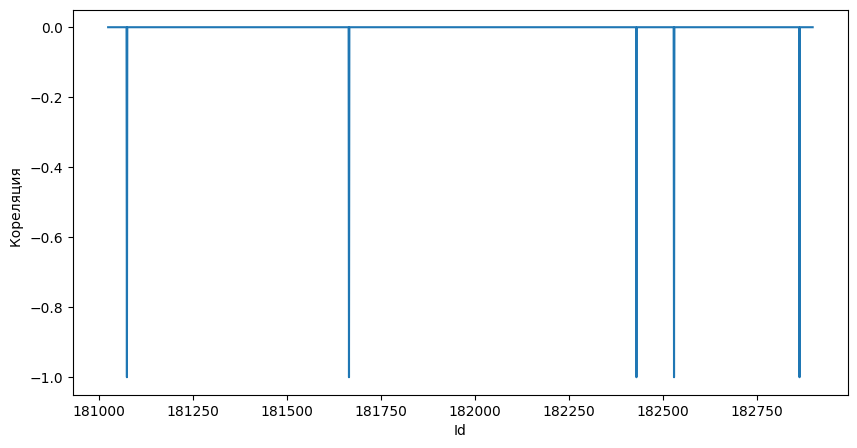

In [4]:
fig = plt.figure(figsize=(10, 5))

scatterplot = sns.lineplot(
    data=photo_df_OK,
    x='Measurement ID',
    #y='P0.TH',
    y='Judge',
    #hue='species',
    #s=100,
    #size='sex',
    sizes=(50, 300)

)
scatterplot.set_title('', fontsize=16)
scatterplot.set_xlabel('Id')
scatterplot.set_ylabel('Кореляция  ')

In [5]:

fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

In [6]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='P0.Y')
fig.show()


In [7]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='I0.CR0')
fig.show()

In [8]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y='P1.TH')
fig.show()

# Предварительно находим ID помеченые браком и убираем их, то есть камера в предварительном режиме уже не обнаружила объект.

In [9]:

photo_df_I0CR00=photo_df_OK[photo_df_OK['Judge']==-1]
len(photo_df_I0CR00)
photo_df_I0CR00.info()
print(photo_df_I0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_I0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 5 entries, 50 to 1840
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 4.5 KB
50      181074
641     181665
1406    182430
1506    182530
1840    182864
Name: Measurement ID, dtype: int64
<class 'pandas.DataFrame'>
Index: 1871 entries, 0 to 1875
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 1.6 MB


# Проверка(график), что отсутсвуют индексы с браком(Judge=-1)

Text(0, 0.5, 'Кореляция  ')

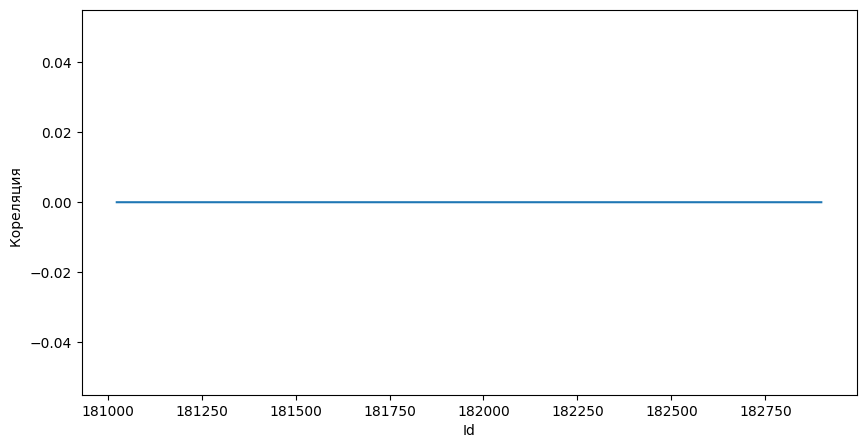

In [10]:


fig = plt.figure(figsize=(10, 5))

scatterplot = sns.lineplot(
    data=photo_df_OK,
    x='Measurement ID',
    #y='P0.TH',
    y='Judge',
    #hue='species',
    #s=100,
    #size='sex',
    sizes=(50, 300)

)
scatterplot.set_title('', fontsize=16)
scatterplot.set_xlabel('Id')
scatterplot.set_ylabel('Кореляция  ')

In [11]:

fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

# Проверка, что PO.CR(в данных это соответсвует коллерция форме крышки в камере), если есть уберём сразу

In [12]:

photo_df_P0CR00=photo_df_OK[photo_df_OK['P0.CR']==0]
len(photo_df_P0CR00)
photo_df_P0CR00.info()
print(photo_df_P0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_P0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 0 entries
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 0.0 bytes
Series([], Name: Measurement ID, dtype: int64)
<class 'pandas.DataFrame'>
Index: 1871 entries, 0 to 1875
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 1.6 MB


In [13]:
photo_df_P0CR00=photo_df_OK[photo_df_OK['P0.JG']==-1.0]
len(photo_df_P0CR00)
photo_df_P0CR00.info()
print(photo_df_P0CR00['Measurement ID'])

mask=photo_df_OK['Measurement ID'].isin(photo_df_P0CR00['Measurement ID'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 15 entries, 122 to 1792
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 13.5 KB
122     181146
218     181242
374     181398
464     181488
483     181507
513     181537
604     181628
623     181647
873     181897
937     181961
973     181997
1100    182124
1142    182166
1636    182660
1792    182816
Name: Measurement ID, dtype: int64
<class 'pandas.DataFrame'>
Index: 1856 entries, 0 to 1875
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 1.6 MB


In [14]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y="P0.CR")
fig.show()

In [15]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y="I0.CR0")
fig.show()

# удаление столбцов где все значение =0

In [16]:

mask_columns=photo_df_OK.columns[(photo_df_OK == 0).all()]
mask_columns = [col for col in mask_columns if col != "Judge"]
print(mask_columns)
photo_df_OK.drop(columns=mask_columns,inplace=True)
photo_df_OK.drop(columns='I0.C',inplace=True)
photo_df_OK.describe()

['Scene No.', 'P0.JG', 'P0.TH', 'I0.TH0', 'I0.CR1', 'I0.Y1', 'I0.TH1', 'I0.CR2', 'I0.Y2', 'I0.TH2', 'I0.CR3', 'I0.Y3', 'I0.TH3', 'I0.CR4', 'I0.Y4', 'I0.TH4', 'I0.CR5', 'I0.Y5', 'I0.TH5', 'I0.CR6', 'I0.Y6', 'I0.TH6', 'I0.CR7', 'I0.Y7', 'I0.TH7', 'I0.CR8', 'I0.Y8', 'I0.TH8', 'I0.CR9', 'I0.Y9', 'I0.TH9', 'I0.CR10', 'I0.Y10', 'I0.TH10', 'I0.CR11', 'I0.Y11', 'I0.TH11', 'I0.CR12', 'I0.Y12', 'I0.TH12', 'I0.CR13', 'I0.Y13', 'I0.TH13', 'I0.CR14', 'I0.Y14', 'I0.TH14', 'I0.CR15', 'I0.Y15', 'I0.TH15', 'I0.CR16', 'I0.Y16', 'I0.TH16', 'I0.CR17', 'I0.Y17', 'I0.TH17', 'I0.CR18', 'I0.Y18', 'I0.TH18', 'I0.CR19', 'I0.Y19', 'I0.TH19', 'I0.CR20', 'I0.Y20', 'I0.TH20', 'I0.CR21', 'I0.Y21', 'I0.TH21', 'I0.CR22', 'I0.Y22', 'I0.TH22', 'I0.CR23', 'I0.Y23', 'I0.TH23', 'I0.CR24', 'I0.Y24', 'I0.TH24', 'I0.CR25', 'I0.Y25', 'I0.TH25', 'I0.CR26', 'I0.Y26', 'I0.TH26', 'I0.CR27', 'I0.Y27', 'I0.TH27', 'I0.CR28', 'I0.Y28', 'I0.TH28', 'I0.CR29', 'I0.Y29', 'I0.TH29', 'I0.CR30', 'I0.Y30', 'I0.TH30', 'I0.CR31', 'I0.Y31', 'I0.

,Measurement ID,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,1856.000000,1856.0,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000
mean,181962.282866,0.0,16.490285,88.483361,280.490285,-0.247186,97.668357,375.752814,-0.705073,97.276424,369.516190
std,541.709708,0.0,9.154000,9.451491,9.154000,2.335829,3.174102,2.335829,1.304801,3.729834,0.228436
min,181024.000000,0.0,-31.942600,60.131900,232.057400,-6.273000,66.666700,369.727000,-5.718800,57.826100,368.448200
25%,181492.750000,0.0,10.562400,83.812700,274.562400,-2.184300,96.536800,373.815700,-1.798200,95.652200,369.377200
50%,181963.500000,0.0,16.298700,91.662300,280.298700,-0.126450,99.134200,375.873550,-0.212500,98.695700,369.509700
75%,182431.250000,0.0,22.416500,95.752000,286.416500,1.307050,100.000000,377.307050,-0.020175,100.000000,369.645825
max,182899.000000,0.0,49.653800,100.000000,313.653800,6.279500,100.000000,382.279500,3.883900,100.000000,370.725800


In [17]:
photo_df_OK = photo_df_OK.reset_index(drop=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
RangeIndex: 1856 entries, 0 to 1855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            1856 non-null   str    
 1   Time            1856 non-null   str    
 2   Measurement ID  1856 non-null   int64  
 3   Judge           1856 non-null   int64  
 4   P0.DY           1856 non-null   float64
 5   P0.CR           1856 non-null   float64
 6   P0.Y            1856 non-null   float64
 7   P1.DY           1856 non-null   float64
 8   P1.CR           1856 non-null   float64
 9   P1.Y            1856 non-null   float64
 10  P1.TH           1856 non-null   float64
 11  I0.CR0          1856 non-null   float64
 12  I0.Y0           1856 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 188.6 KB


In [18]:
fig = px.scatter(photo_df_OK, x='Measurement ID', y=['P0.DY','P0.CR','P0.Y','P1.DY',"P1.CR",'P1.Y','P1.TH','I0.CR0','I0.Y0'])
fig.show()


In [19]:
photo_df_OK.describe()

,Measurement ID,Judge,P0.DY,P0.CR,P0.Y,P1.DY,P1.CR,P1.Y,P1.TH,I0.CR0,I0.Y0
count,1856.000000,1856.0,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000
mean,181962.282866,0.0,16.490285,88.483361,280.490285,-0.247186,97.668357,375.752814,-0.705073,97.276424,369.516190
std,541.709708,0.0,9.154000,9.451491,9.154000,2.335829,3.174102,2.335829,1.304801,3.729834,0.228436
min,181024.000000,0.0,-31.942600,60.131900,232.057400,-6.273000,66.666700,369.727000,-5.718800,57.826100,368.448200
25%,181492.750000,0.0,10.562400,83.812700,274.562400,-2.184300,96.536800,373.815700,-1.798200,95.652200,369.377200
50%,181963.500000,0.0,16.298700,91.662300,280.298700,-0.126450,99.134200,375.873550,-0.212500,98.695700,369.509700
75%,182431.250000,0.0,22.416500,95.752000,286.416500,1.307050,100.000000,377.307050,-0.020175,100.000000,369.645825
max,182899.000000,0.0,49.653800,100.000000,313.653800,6.279500,100.000000,382.279500,3.883900,100.000000,370.725800


# Здесь дропаем признаки которые точно не нужны, время даты и т.п.
Так же убираем P0.Y и P1.Y эти признаки определяют на какой высоте найдены признаки в изображение камеры, что пагубно повлияет на обобщающей способности модели. При малейшем изменение высоты колпака будет давать сильные изменения и будет требовать переобучения модели. Полезней использовать такие параметры как разница обнаружения от эталона PO.DY и P1.DY. А ведь может бутылка и выше стать и фокус сместиться. Корреляция так же уберём

In [20]:
photo_df_OK.drop(columns=["Measurement ID",'Date','Time','P0.Y','P1.Y','I0.CR0','I0.Y0'],inplace=True)
photo_df_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,1856.0,1856.000000,1856.000000,1856.000000,1856.000000,1856.000000
mean,0.0,16.490285,88.483361,-0.247186,97.668357,-0.705073
std,0.0,9.154000,9.451491,2.335829,3.174102,1.304801
min,0.0,-31.942600,60.131900,-6.273000,66.666700,-5.718800
25%,0.0,10.562400,83.812700,-2.184300,96.536800,-1.798200
50%,0.0,16.298700,91.662300,-0.126450,99.134200,-0.212500
75%,0.0,22.416500,95.752000,1.307050,100.000000,-0.020175
max,0.0,49.653800,100.000000,6.279500,100.000000,3.883900


[[ 1.          0.54293691  0.7856286   0.5966377  -0.02168144]
 [ 0.54293691  1.          0.63211175  0.56062709 -0.06248561]
 [ 0.7856286   0.63211175  1.          0.54317505  0.00288306]
 [ 0.5966377   0.56062709  0.54317505  1.         -0.11085805]
 [-0.02168144 -0.06248561  0.00288306 -0.11085805  1.        ]]
(5, 5)


<Axes: >

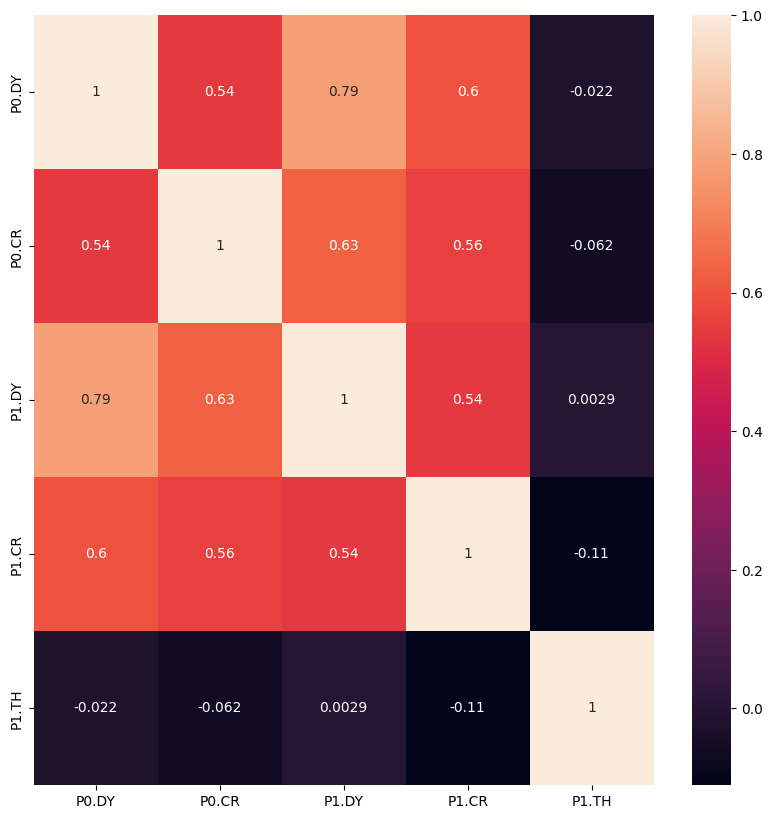

In [21]:

photo_df_OK.head()
#print(photo_df)
#y=df['Performance Index']

#n=len(photo_df['P0.Y'])

X_future=photo_df_OK.drop(columns='Judge')
X=photo_df_OK.drop(columns='Judge').values

#cтандартизация данных таблицы
X_std=(X-X.mean(axis=0))/X.std(axis=0,ddof=1)

#стандартизация вектора столбцов

X_std_cov=(X_std.T@X_std)/(X_std.shape[0]-1)




print(X_std_cov)
print(X_std_cov.shape)
plt.figure(figsize=(10, 10))
sns.heatmap(X_std_cov,annot=True,xticklabels=X_future.columns,
            yticklabels=X_future.columns)




In [22]:
fig = px.scatter(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'])
fig.show()


In [23]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v')
fig.show()


только для не брака

In [24]:
photo_df_P0DY=photo_df_OK[photo_df_OK['P0.DY']<-30]


mask=photo_df_OK['P0.DY'].isin(photo_df_P0DY['P0.DY'])
photo_df_OK.drop(photo_df_OK[mask].index,inplace=True)
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 1855 entries, 0 to 1855
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   1855 non-null   int64  
 1   P0.DY   1855 non-null   float64
 2   P0.CR   1855 non-null   float64
 3   P1.DY   1855 non-null   float64
 4   P1.CR   1855 non-null   float64
 5   P1.TH   1855 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 101.4 KB


In [25]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v',title='НЕ Брак')
fig.show()


# Z обрезание данных не брака(очищаем от выбросов)

In [26]:
def  outliers_z_score_mod(data, feature, log_scale=False,left=3,right=3):
    if log_scale:
        x = np.log(data[feature]+1)
    else:
        x = data[feature]
    mu = x.mean()
    sigma = x.std()
    lower_bound = mu - left * sigma
    upper_bound = mu + right * sigma
    outliers = data[(x < lower_bound) | (x > upper_bound)]
    cleaned = data[(x >= lower_bound) & (x <= upper_bound)]
    return outliers, cleaned

In [27]:
for col in photo_df_OK.columns:
    outliers, photo_df_OK = outliers_z_score_mod(photo_df_OK, col ,left=1.5,right=1.5) #Здесь ужесточим границу
    print(f'Число выбросов по методу z-отклонения в колонке {col}: {outliers.shape[0]}')
    print(f'Результирующее число записей: {photo_df_OK.shape[0]}')

Число выбросов по методу z-отклонения в колонке Judge: 0
Результирующее число записей: 1855
Число выбросов по методу z-отклонения в колонке P0.DY: 238
Результирующее число записей: 1617
Число выбросов по методу z-отклонения в колонке P0.CR: 183
Результирующее число записей: 1434
Число выбросов по методу z-отклонения в колонке P1.DY: 220
Результирующее число записей: 1214
Число выбросов по методу z-отклонения в колонке P1.CR: 116
Результирующее число записей: 1098
Число выбросов по методу z-отклонения в колонке P1.TH: 153
Результирующее число записей: 945


In [28]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v')
fig.show()


In [29]:
photo_df_OK.info()

<class 'pandas.DataFrame'>
Index: 945 entries, 0 to 1855
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   945 non-null    int64  
 1   P0.DY   945 non-null    float64
 2   P0.CR   945 non-null    float64
 3   P1.DY   945 non-null    float64
 4   P1.CR   945 non-null    float64
 5   P1.TH   945 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 51.7 KB


In [30]:
photo_df_OK.value_counts()

Judge  P0.DY    P0.CR     P1.DY    P1.CR     P1.TH  
0      20.4091  96.9393    1.5569  100.0000  -0.1042    1
       13.8259  82.6913   -1.5121  99.1342   -0.1231    1
       14.4908  94.6174    2.2530  100.0000  -0.1480    1
       27.0510  92.5594    2.8166  100.0000  -1.9292    1
       28.4159  97.8892    2.6688  100.0000  -1.9506    1
                                                       ..
       25.3118  97.6253    0.2715  100.0000  -1.9447    1
       13.9724  94.9868   -0.5290  99.5671    0.0240    1
       23.2732  100.0000   2.5702  100.0000  -1.8169    1
       9.3384   83.7203   -0.6034  100.0000  -0.1935    1
       24.5000  97.9683    1.7898  100.0000  -0.0888    1
Name: count, Length: 945, dtype: int64

# Обработка данных брака

In [31]:
photo_df_NG=pd.read_csv(f"14112025cam2_2026_01_27-10_36_41_NG.csv")
photo_df_NG.info()

<class 'pandas.DataFrame'>
RangeIndex: 646 entries, 0 to 645
Columns: 114 entries, Date to Z0.D00
dtypes: float64(109), int64(3), str(2)
memory usage: 575.5 KB


# Обработка информации по браку

In [32]:
photo_df_NG.value_counts()

Date       Time      Measurement ID  Scene No.  Judge  P0.JG  P0.DY     P0.CR    P0.Y      P0.TH  P1.DY     P1.CR    P1.Y      P1.TH    I0.C  I0.CR0   I0.Y0     I0.TH0  I0.CR1  I0.Y1  I0.TH1  I0.CR2  I0.Y2  I0.TH2  I0.CR3  I0.Y3  I0.TH3  I0.CR4  I0.Y4  I0.TH4  I0.CR5  I0.Y5  I0.TH5  I0.CR6  I0.Y6  I0.TH6  I0.CR7  I0.Y7  I0.TH7  I0.CR8  I0.Y8  I0.TH8  I0.CR9  I0.Y9  I0.TH9  I0.CR10  I0.Y10  I0.TH10  I0.CR11  I0.Y11  I0.TH11  I0.CR12  I0.Y12  I0.TH12  I0.CR13  I0.Y13  I0.TH13  I0.CR14  I0.Y14  I0.TH14  I0.CR15  I0.Y15  I0.TH15  I0.CR16  I0.Y16  I0.TH16  I0.CR17  I0.Y17  I0.TH17  I0.CR18  I0.Y18  I0.TH18  I0.CR19  I0.Y19  I0.TH19  I0.CR20  I0.Y20  I0.TH20  I0.CR21  I0.Y21  I0.TH21  I0.CR22  I0.Y22  I0.TH22  I0.CR23  I0.Y23  I0.TH23  I0.CR24  I0.Y24  I0.TH24  I0.CR25  I0.Y25  I0.TH25  I0.CR26  I0.Y26  I0.TH26  I0.CR27  I0.Y27  I0.TH27  I0.CR28  I0.Y28  I0.TH28  I0.CR29  I0.Y29  I0.TH29  I0.CR30  I0.Y30  I0.TH30  I0.CR31  I0.Y31  I0.TH31  Z0.JG  Z0.J00  Z0.D00
2026/1/27  10:36:41  862814   

In [33]:
photo_df_NG['Judge']=-1
photo_df_NG.value_counts()

Date       Time      Measurement ID  Scene No.  Judge  P0.JG  P0.DY     P0.CR    P0.Y      P0.TH  P1.DY     P1.CR    P1.Y      P1.TH    I0.C  I0.CR0   I0.Y0     I0.TH0  I0.CR1  I0.Y1  I0.TH1  I0.CR2  I0.Y2  I0.TH2  I0.CR3  I0.Y3  I0.TH3  I0.CR4  I0.Y4  I0.TH4  I0.CR5  I0.Y5  I0.TH5  I0.CR6  I0.Y6  I0.TH6  I0.CR7  I0.Y7  I0.TH7  I0.CR8  I0.Y8  I0.TH8  I0.CR9  I0.Y9  I0.TH9  I0.CR10  I0.Y10  I0.TH10  I0.CR11  I0.Y11  I0.TH11  I0.CR12  I0.Y12  I0.TH12  I0.CR13  I0.Y13  I0.TH13  I0.CR14  I0.Y14  I0.TH14  I0.CR15  I0.Y15  I0.TH15  I0.CR16  I0.Y16  I0.TH16  I0.CR17  I0.Y17  I0.TH17  I0.CR18  I0.Y18  I0.TH18  I0.CR19  I0.Y19  I0.TH19  I0.CR20  I0.Y20  I0.TH20  I0.CR21  I0.Y21  I0.TH21  I0.CR22  I0.Y22  I0.TH22  I0.CR23  I0.Y23  I0.TH23  I0.CR24  I0.Y24  I0.TH24  I0.CR25  I0.Y25  I0.TH25  I0.CR26  I0.Y26  I0.TH26  I0.CR27  I0.Y27  I0.TH27  I0.CR28  I0.Y28  I0.TH28  I0.CR29  I0.Y29  I0.TH29  I0.CR30  I0.Y30  I0.TH30  I0.CR31  I0.Y31  I0.TH31  Z0.JG  Z0.J00  Z0.D00
2026/1/27  10:36:41  862814   

In [34]:
photo_df_NG.nunique()
photo_df_NG.drop(columns=['Date','Time','P0.Y','P1.Y','P0.JG', 'Z0.JG',	'Z0.J00','Z0.D00','Measurement ID'],inplace=True)

In [35]:
photo_df_NG.nunique()

Scene No.      1
Judge          1
P0.DY        131
P0.CR        257
P0.TH          1
            ... 
I0.Y30         1
I0.TH30        1
I0.CR31        1
I0.Y31         1
I0.TH31        1
Length: 105, dtype: int64

In [36]:
#удаление столбцов где все значение =0
mask_columns=photo_df_NG.columns[(photo_df_NG == 0).all()]
mask_columns = [col for col in mask_columns if col != "Judge"]
print(mask_columns)
photo_df_NG.drop(columns=mask_columns,inplace=True)
photo_df_NG.drop(columns='I0.C',inplace=True)
photo_df_NG.describe()

['Scene No.', 'P0.TH', 'I0.TH0', 'I0.CR1', 'I0.Y1', 'I0.TH1', 'I0.CR2', 'I0.Y2', 'I0.TH2', 'I0.CR3', 'I0.Y3', 'I0.TH3', 'I0.CR4', 'I0.Y4', 'I0.TH4', 'I0.CR5', 'I0.Y5', 'I0.TH5', 'I0.CR6', 'I0.Y6', 'I0.TH6', 'I0.CR7', 'I0.Y7', 'I0.TH7', 'I0.CR8', 'I0.Y8', 'I0.TH8', 'I0.CR9', 'I0.Y9', 'I0.TH9', 'I0.CR10', 'I0.Y10', 'I0.TH10', 'I0.CR11', 'I0.Y11', 'I0.TH11', 'I0.CR12', 'I0.Y12', 'I0.TH12', 'I0.CR13', 'I0.Y13', 'I0.TH13', 'I0.CR14', 'I0.Y14', 'I0.TH14', 'I0.CR15', 'I0.Y15', 'I0.TH15', 'I0.CR16', 'I0.Y16', 'I0.TH16', 'I0.CR17', 'I0.Y17', 'I0.TH17', 'I0.CR18', 'I0.Y18', 'I0.TH18', 'I0.CR19', 'I0.Y19', 'I0.TH19', 'I0.CR20', 'I0.Y20', 'I0.TH20', 'I0.CR21', 'I0.Y21', 'I0.TH21', 'I0.CR22', 'I0.Y22', 'I0.TH22', 'I0.CR23', 'I0.Y23', 'I0.TH23', 'I0.CR24', 'I0.Y24', 'I0.TH24', 'I0.CR25', 'I0.Y25', 'I0.TH25', 'I0.CR26', 'I0.Y26', 'I0.TH26', 'I0.CR27', 'I0.Y27', 'I0.TH27', 'I0.CR28', 'I0.Y28', 'I0.TH28', 'I0.CR29', 'I0.Y29', 'I0.TH29', 'I0.CR30', 'I0.Y30', 'I0.TH30', 'I0.CR31', 'I0.Y31', 'I0.TH31']


,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH,I0.CR0,I0.Y0
count,646.0,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000
mean,-1.0,-2.428801,28.198657,-12.747530,49.736379,-0.145611,74.611053,329.906079
std,0.0,8.712363,31.373044,17.670046,43.027271,2.581295,22.375510,91.924932
min,-1.0,-41.383700,0.000000,-58.979200,0.000000,-7.801000,0.000000,0.000000
25%,-1.0,0.000000,0.000000,-26.731050,0.000000,-0.228725,70.869600,325.093425
50%,-1.0,0.000000,0.000000,-2.797250,75.324700,0.000000,80.434800,369.345700
75%,-1.0,0.000000,57.539600,0.000000,89.177500,0.233950,87.380425,369.741550
max,-1.0,41.000000,96.306100,21.751300,100.000000,7.400300,100.000000,388.244100


In [37]:
for col in photo_df_NG.columns:
    outliers, photo_df_NG = outliers_z_score_mod(photo_df_NG, col ,left=3,right=3) #Здесь ужесточим границу
    print(f'Число выбросов по методу z-отклонения в колонке {col}: {outliers.shape[0]}')
    print(f'Результирующее число записей: {photo_df_NG.shape[0]}')

Число выбросов по методу z-отклонения в колонке Judge: 0
Результирующее число записей: 646
Число выбросов по методу z-отклонения в колонке P0.DY: 26
Результирующее число записей: 620
Число выбросов по методу z-отклонения в колонке P0.CR: 0
Результирующее число записей: 620
Число выбросов по методу z-отклонения в колонке P1.DY: 0
Результирующее число записей: 620
Число выбросов по методу z-отклонения в колонке P1.CR: 0
Результирующее число записей: 620
Число выбросов по методу z-отклонения в колонке P1.TH: 0
Результирующее число записей: 620
Число выбросов по методу z-отклонения в колонке I0.CR0: 44
Результирующее число записей: 576
Число выбросов по методу z-отклонения в колонке I0.Y0: 0
Результирующее число записей: 576


# Контрольный график признаков NG

In [38]:
fig = px.box(photo_df_NG, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v',title='Брак')
fig.show()


In [39]:
fig = px.box(photo_df_OK, y=['P0.DY','P0.CR','P1.DY',"P1.CR",'P1.TH'],orientation='v',title='НЕ Брак')
fig.show()


# Приводим количество колонок в DF брака и не брака к одному количеству.

In [40]:
photo_df_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000
mean,0.0,17.794271,92.889084,0.202042,99.126733,-0.814499
std,0.0,5.820763,4.989029,1.485266,1.199723,0.870205
min,0.0,4.192300,77.546200,-2.671600,95.368000,-2.297800
25%,0.0,13.529200,90.131900,-0.739000,98.701300,-1.791300
50%,0.0,18.182900,93.957800,0.015500,99.697000,-0.228500
75%,0.0,21.731400,96.675500,1.231000,100.000000,-0.072100
max,0.0,30.014900,100.000000,2.968800,100.000000,0.312500


In [41]:
photo_df_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH,I0.CR0,I0.Y0
count,576.0,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000
mean,-1.0,-1.732812,28.355046,-14.169928,52.252817,-0.145493,79.842393,353.274603
std,0.0,5.961376,30.826068,18.192618,42.650688,2.677630,10.025228,22.992937
min,-1.0,-28.394700,0.000000,-58.979200,0.000000,-7.801000,51.739100,310.806600
25%,-1.0,0.000000,0.000000,-29.289900,0.000000,-0.279225,72.608700,330.362500
50%,-1.0,0.000000,0.000000,-3.262800,77.013000,0.000000,81.304300,369.377850
75%,-1.0,0.000000,57.044900,0.000000,89.610400,0.364700,87.391300,369.754325
max,-1.0,22.590900,95.013200,21.751300,100.000000,7.400300,100.000000,388.244100


In [42]:

photo_df_NG.drop(columns=['I0.CR0','I0.Y0'],inplace=True)
print(photo_df_NG.info())
print(photo_df_OK.info())

<class 'pandas.DataFrame'>
Index: 576 entries, 1 to 645
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   576 non-null    int64  
 1   P0.DY   576 non-null    float64
 2   P0.CR   576 non-null    float64
 3   P1.DY   576 non-null    float64
 4   P1.CR   576 non-null    float64
 5   P1.TH   576 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 31.5 KB
None
<class 'pandas.DataFrame'>
Index: 945 entries, 0 to 1855
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Judge   945 non-null    int64  
 1   P0.DY   945 non-null    float64
 2   P0.CR   945 non-null    float64
 3   P1.DY   945 non-null    float64
 4   P1.CR   945 non-null    float64
 5   P1.TH   945 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 51.7 KB
None


# Объединяем в общий DataFrame брак и не брак

In [43]:
photo_df=pd.concat([photo_df_OK,photo_df_NG],ignore_index=True)
photo_df.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
count,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000
mean,-0.378698,10.399399,68.450158,-5.240597,81.375664,-0.561148
std,0.485222,11.147237,36.816472,13.236470,34.732333,1.813255
min,-1.000000,-28.394700,0.000000,-58.979200,0.000000,-7.801000
25%,-1.000000,0.000000,54.432700,-2.093700,86.147200,-1.775900
50%,0.000000,12.900000,88.971000,-0.120800,98.268400,-0.131400
75%,0.000000,19.629500,95.224300,0.338300,100.000000,0.000000
max,0.000000,30.014900,100.000000,21.751300,100.000000,7.400300


In [44]:
photo_df.reset_index()

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
0,0,0,20.4091,96.9393,1.5569,100.0000,-0.1042
1,1,0,13.8259,82.6913,-1.5121,99.1342,-0.1231
2,2,0,14.4908,94.6174,2.2530,100.0000,-0.1480
3,3,0,27.0510,92.5594,2.8166,100.0000,-1.9292
4,4,0,28.4159,97.8892,2.6688,100.0000,-1.9506
...,...,...,...,...,...,...,...
1516,1516,-1,0.0000,50.4222,-42.4397,93.0303,1.9259
1517,1517,-1,0.0000,0.0000,0.0000,0.0000,0.0000
1518,1518,-1,0.0000,0.0000,0.0000,0.0000,0.0000
1519,1519,-1,0.0000,0.0000,-49.2938,70.5628,-0.1103


In [45]:
photo_df = photo_df.sample(frac=1,random_state=42).reset_index(drop=True)
photo_df.reset_index()


#photo_df['P1.THSin'] = photo_df['P1.TH'].apply(lambda x: abs(math.sin(np.radians(x))))

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH
0,0,0,12.9759,97.0976,0.2793,98.7013,0.0737
1,1,-1,0.0000,59.6570,-31.6458,93.5065,1.5032
2,2,-1,0.0000,0.0000,0.0000,0.0000,0.0000
3,3,-1,-11.3889,67.2823,-0.7643,99.1342,3.7500
4,4,-1,0.0000,0.0000,-49.0625,71.8615,0.3635
...,...,...,...,...,...,...,...
1516,1516,-1,0.0000,0.0000,-56.3250,70.5628,0.3261
1517,1517,-1,0.0000,59.9472,-29.9710,91.3420,-0.1313
1518,1518,0,17.1712,91.2137,-0.9550,97.8355,-0.2541
1519,1519,-1,0.0000,50.6596,-15.7689,90.0433,5.6250


# Добавление признака "sin" угла крышки относительно кромки по модулю

In [46]:
angle_rad = np.radians(photo_df['P1.TH'])
photo_df['P1.angle_sin'] = abs(np.sin(angle_rad))
photo_df['P0.CR']=photo_df['P0.CR']/100 #Здесь нормализируем к 0-1 корееляция фиксированая от 0 100
photo_df['P1.CR']=photo_df['P1.CR']/100
photo_df['P1.DY']=(photo_df['P1.DY']-(-100))/(100-(-100))#Здесь уже DY фактически может и 100 и + 100 приводим по формуле
photo_df['P0.DY']=(photo_df['P0.DY']-(-100))/(100-(-100))#Здесь уже DY фактически может и 100 и + 100 приводим по формуле
#df['angle_cos'] = np.cos(angle_rad)
#angle_rad = np.radians(photo_df['P1.TH'])
#photo_df['P1.angle_sin'] = abs(np.sin(angle_rad))

In [47]:
photo_df.reset_index()

,index,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.TH,P1.angle_sin
0,0,0,0.564879,0.970976,0.501397,0.987013,0.0737,0.001286
1,1,-1,0.500000,0.596570,0.341771,0.935065,1.5032,0.026233
2,2,-1,0.500000,0.000000,0.500000,0.000000,0.0000,0.000000
3,3,-1,0.443055,0.672823,0.496178,0.991342,3.7500,0.065403
4,4,-1,0.500000,0.000000,0.254688,0.718615,0.3635,0.006344
...,...,...,...,...,...,...,...,...
1516,1516,-1,0.500000,0.000000,0.218375,0.705628,0.3261,0.005691
1517,1517,-1,0.500000,0.599472,0.350145,0.913420,-0.1313,0.002292
1518,1518,0,0.585856,0.912137,0.495225,0.978355,-0.2541,0.004435
1519,1519,-1,0.500000,0.506596,0.421156,0.900433,5.6250,0.098017


In [48]:
#Убираем признак Угол тангенс  P1.TH
photo_df.drop(columns=['P1.TH'],inplace=True)
#photo_df.dropna(inplace=True,axis=1)
photo_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1521 entries, 0 to 1520
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Judge         1521 non-null   int64  
 1   P0.DY         1521 non-null   float64
 2   P0.CR         1521 non-null   float64
 3   P1.DY         1521 non-null   float64
 4   P1.CR         1521 non-null   float64
 5   P1.angle_sin  1521 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 71.4 KB


[[ 1.          0.84998429  0.85052565  0.52684743  0.65484426 -0.2837091 ]
 [ 0.84998429  1.          0.67276407  0.42334877  0.49832174 -0.25546122]
 [ 0.85052565  0.67276407  1.          0.48332954  0.77354182 -0.07266571]
 [ 0.52684743  0.42334877  0.48332954  1.         -0.00561356 -0.42698642]
 [ 0.65484426  0.49832174  0.77354182 -0.00561356  1.          0.24883591]
 [-0.2837091  -0.25546122 -0.07266571 -0.42698642  0.24883591  1.        ]]
(6, 6)


<Axes: >

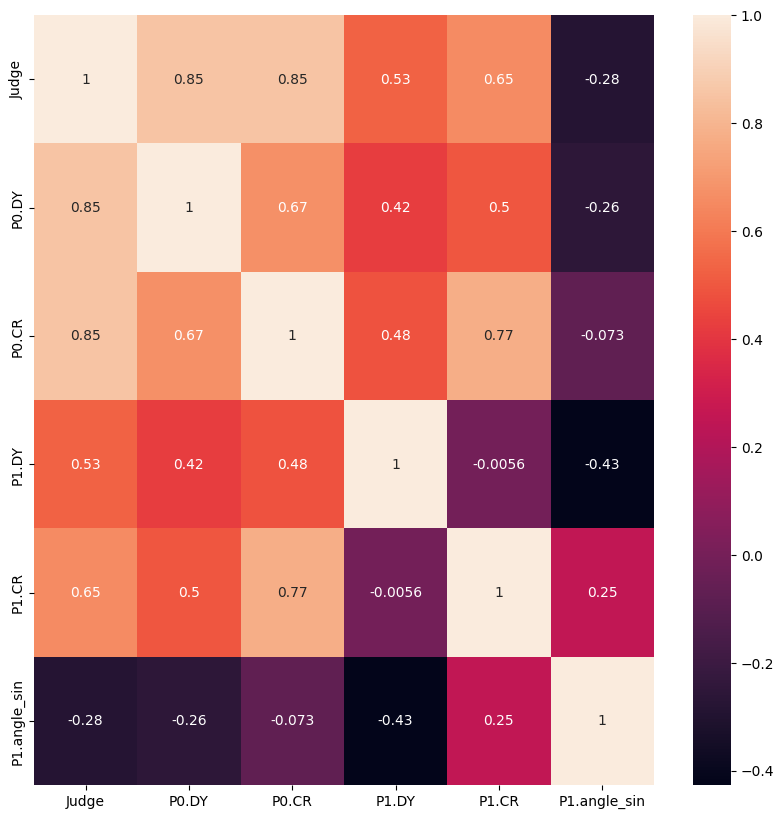

In [49]:
photo_df.head()



X=photo_df.values

#cтандартизация данных таблицы
X_std=(X-X.mean(axis=0))/X.std(axis=0,ddof=1)

X_std_cov=(X_std.T@X_std)/(X_std.shape[0]-1)


print(X_std_cov)
print(X_std_cov.shape)
plt.figure(figsize=(10, 10))
sns.heatmap(X_std_cov,annot=True,xticklabels=photo_df.columns,
            yticklabels=photo_df.columns)

# Итоговое распределение данных

Проверка распределения

АНАЛИЗ РАСПРЕДЕЛЕНИЯ КЛАССОВ
Текущая бинаризация (Judge == 0):
  Класс 1 (Judge == 0): 945 примеров (62.1%)
  Класс 0 (Judge != 0): 576 примеров (37.9%)

Альтернативная бинаризация (Judge > 0):
  Класс 1 (Judge > 0): 0 примеров (0.0%)
  Класс 0 (Judge ≤ 0): 1521 примеров (100.0%)

Статистика значений Judge:
  Минимум: -1
  Максимум: 0
  Среднее: -0.38
  Медиана: 0.00
  Уникальные значения: 2

Количество Judge = 0: 945 (62.1%)
Количество Judge > 0: 0 (0.0%)
Количество Judge < 0: 576 (37.9%)


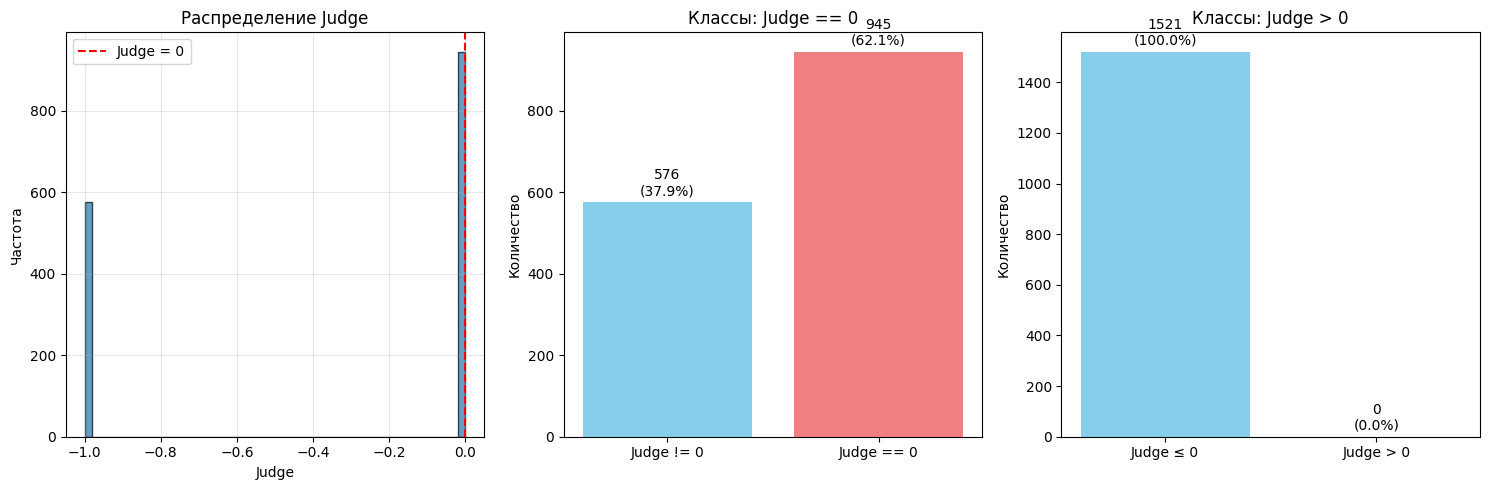


РЕКОМЕНДАЦИИ ПО ВЫБОРУ ПОРОГА
Распределение разумное. Можно использовать Judge == 0 как порог.

Используемая бинаризация:
  Класс 1: 945 примеров (62.1%)
  Класс 0: 576 примеров (37.9%)


In [50]:
# Проверка распределения классов
print("=" * 80)
print("АНАЛИЗ РАСПРЕДЕЛЕНИЯ КЛАССОВ")
print("=" * 80)

y=photo_df['Judge']


y=photo_df['Judge'].values
df=photo_df.drop(columns=["Judge"])
len(df.columns)
X=df.values

# Ваш текущий подход: Judge == 0
y_binary_eq = (y == 0).astype(int)
print("Текущая бинаризация (Judge == 0):")
print(f"  Класс 1 (Judge == 0): {(y_binary_eq == 1).sum()} примеров ({(y_binary_eq == 1).sum()/len(y):.1%})")
print(f"  Класс 0 (Judge != 0): {(y_binary_eq == 0).sum()} примеров ({(y_binary_eq == 0).sum()/len(y):.1%})")

# Альтернативный подход: Judge > 0
y_binary_gt = (y > 0).astype(int)
print("\nАльтернативная бинаризация (Judge > 0):")
print(f"  Класс 1 (Judge > 0): {(y_binary_gt == 1).sum()} примеров ({(y_binary_gt == 1).sum()/len(y):.1%})")
print(f"  Класс 0 (Judge ≤ 0): {(y_binary_gt == 0).sum()} примеров ({(y_binary_gt == 0).sum()/len(y):.1%})")

# Анализ значений Judge
print("\nСтатистика значений Judge:")
print(f"  Минимум: {y.min()}")
print(f"  Максимум: {y.max()}")
print(f"  Среднее: {y.mean():.2f}")
print(f"  Медиана: {np.median(y):.2f}")
print(f"  Уникальные значения: {len(np.unique(y))}")

# Проверяем, сколько Judge = 0
zero_count = np.sum(y == 0)
print(f"\nКоличество Judge = 0: {zero_count} ({(zero_count/len(y)*100):.1f}%)")

# Проверяем, сколько Judge > 0
positive_count = np.sum(y > 0)
print(f"Количество Judge > 0: {positive_count} ({(positive_count/len(y)*100):.1f}%)")

# Проверяем, сколько Judge < 0  
negative_count = np.sum(y < 0)
print(f"Количество Judge < 0: {negative_count} ({(negative_count/len(y)*100):.1f}%)")


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Гистограмма Judge
axes[0].hist(y, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(x=0, color='red', linestyle='--', label='Judge = 0')
axes[0].set_title('Распределение Judge')
axes[0].set_xlabel('Judge')
axes[0].set_ylabel('Частота')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Распределение классов при Judge == 0
class_counts_eq = [np.sum(y_binary_eq == 0), np.sum(y_binary_eq == 1)]
axes[1].bar(['Judge != 0', 'Judge == 0'], class_counts_eq, color=['skyblue', 'lightcoral'])
axes[1].set_title('Классы: Judge == 0')
axes[1].set_ylabel('Количество')
for i, v in enumerate(class_counts_eq):
    axes[1].text(i, v + max(class_counts_eq)*0.01, f'{v}\n({v/len(y)*100:.1f}%)', 
                ha='center', va='bottom')

# Распределение классов при Judge > 0
class_counts_gt = [np.sum(y_binary_gt == 0), np.sum(y_binary_gt == 1)]
axes[2].bar(['Judge ≤ 0', 'Judge > 0'], class_counts_gt, color=['skyblue', 'lightcoral'])
axes[2].set_title('Классы: Judge > 0')
axes[2].set_ylabel('Количество')
for i, v in enumerate(class_counts_gt):
    axes[2].text(i, v + max(class_counts_gt)*0.01, f'{v}\n({v/len(y)*100:.1f}%)', 
                ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Рекомендация по выбору порога
print("\n" + "=" * 80)
print("РЕКОМЕНДАЦИИ ПО ВЫБОРУ ПОРОГА")
print("=" * 80)

if zero_count < 0.05 * len(y):  # Меньше 5% нулей
    print("СЛИШКОМ МАЛО Judge = 0! Логистическая регрессия может не сходиться.")
    print("Рекомендация: использовать Judge > 0 как порог")
    y_binary = y_binary_gt
elif zero_count > 0.95 * len(y):  # Больше 95% нулей
    print("СЛИШКОМ МНОГО Judge = 0! Логистическая регрессия может не сходиться.")
    print("Рекомендация: использовать Judge > 0 как порог")
    y_binary = y_binary_gt
else:
    print("Распределение разумное. Можно использовать Judge == 0 как порог.")
    y_binary = y_binary_eq

print(f"\nИспользуемая бинаризация:")
print(f"  Класс 1: {np.sum(y_binary == 1)} примеров ({(np.sum(y_binary == 1)/len(y)*100):.1f}%)")
print(f"  Класс 0: {np.sum(y_binary == 0)} примеров ({(np.sum(y_binary == 0)/len(y)*100):.1f}%)")

In [51]:
#list_p1dy=photo_df['P1.DY']
#list_p0dy=photo_df['P0.DY']
#photo_df['P0.DY']=list_p1dy
#photo_df['P1.DY']=list_p0dy

In [52]:
photo_df.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin
count,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000
mean,-0.378698,0.551997,0.684502,0.473797,0.813757,0.020406
std,0.485222,0.055736,0.368165,0.066182,0.347323,0.026051
min,-1.000000,0.358027,0.000000,0.205104,0.000000,0.000000
25%,-1.000000,0.500000,0.544327,0.489532,0.861472,0.001091
50%,0.000000,0.564500,0.889710,0.499396,0.982684,0.004306
75%,0.000000,0.598148,0.952243,0.501692,1.000000,0.032485
max,0.000000,0.650075,1.000000,0.608757,1.000000,0.135733


# Обучение модели
Применяем готовую библиотеку Sklearn

In [53]:
df_X=photo_df.drop(columns=['Judge'])
X=df_X.values
df_y=photo_df['Judge']
y=df_y.values


In [54]:

X_train,X_test,y_train,y_test=model_selection.train_test_split(X,y,test_size=0.3,random_state=42)
df_y_train=pd.DataFrame(y_train)
df_y_test=pd.DataFrame(y_test)
print(df_y_train.value_counts())
print(df_y_test.value_counts())

0 
 0    660
-1    404
Name: count, dtype: int64
0 
 0    285
-1    172
Name: count, dtype: int64


In [55]:
clf = LogisticRegression(random_state=99,max_iter=100000,solver='newton-cholesky',C=1).fit(X_train, y_train)

y_pred_test=clf.predict(X_test)



In [56]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 163
FP: 9
FN: 0
TP: 285


In [57]:
# 1. Получаем вероятности от обученной модели
y_pred = clf.predict_proba(X_test)[:, 1]  # вероятности для класса 1

# 2. Выбираем свой порог
my_threshold = 0.7085  # например, смещаем вниз

# 3. Получаем предсказания с новым порогом
y_pred = np.where(y_pred >= my_threshold, 0, -1)

# 4. Считаем матрицу ошибок
cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
print(cm)

# 5. Извлекаем значения (если нужно по отдельности)
tn, fp, fn, tp = cm.ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)
f1 = f1_score(y_test, y_pred, pos_label=0)

print(f"Precision (Точность): {precision:.4f}")
print(f"Recall (Полнота):     {recall:.4f}")
print(f"F1-Score:             {f1:.4f}\n")

Матрица ошибок:
[[168   4]
 [  0 285]]
TN: 168
FP: 4
FN: 0
TP: 285
Precision (Точность): 0.9862
Recall (Полнота):     1.0000
F1-Score:             0.9930



Для реального производства, в моём случае было важнее сохранить, чтоб у нас был как можно меньше ложно негативных срабатываний т.е. минимизировать случаи не брак помечается как брак. На ячейке кода можно отработать этот порог вероятности. Который и будет ориентиром для настройки в камере Omron FQ2.

# Метрики

In [58]:
clf.score(X_test, y_test)

0.9803063457330415

In [59]:
clf.score(X, y)

0.9822485207100592

In [60]:
# Define the number of folds for cross-validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=15)

In [61]:

scores = cross_val_score(clf, X, y, cv=kf)
print(scores)

[0.96065574 0.98355263 0.98355263 0.98355263 1.        ]


In [62]:
mean_scores=np.mean(scores)
print(mean_scores)

0.982262726488352


# обучение на всём датасете

In [63]:
clf.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",99
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multicl

In [64]:
coef=clf.coef_
intercept=clf.intercept_
full_params=np.concatenate([intercept.reshape(-1,1),coef],axis=1)
print(coef)
print(intercept)
print(full_params)
y_pred=clf.predict(X)

[[ 5.25437272 10.63921672  2.03333176  3.81023929 -1.62480919]]
[-14.71457128]
[[-14.71457128   5.25437272  10.63921672   2.03333176   3.81023929
   -1.62480919]]


In [65]:
print(y_pred)
print(y)
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred,pos_label=0)
recall = recall_score(y, y_pred,pos_label=0)
f1 = f1_score(y, y_pred,pos_label=0)
print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1-score: {f1}')

[ 0 -1 -1 ...  0 -1 -1]
[ 0 -1 -1 ...  0 -1 -1]
Accuracy: 0.9848783694937541
Precision: 0.9762396694214877
Recall: 1.0
F1-score: 0.9879769994772608


In [66]:
tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 553
FP: 23
FN: 0
TP: 945


In [67]:
len(X)
def sigmoid(z):
    """Сигмоидная функция активации"""
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [68]:

X1 = np.append(np.ones((len(X), 1)), X, axis=1)
Y=X1@full_params.T



for ind in range(len(Y)):
    print(f"Значение {Y[ind]} Значение sigma {sigmoid(Y[ind])} Значение DataFrame {y[ind]}")
print(Y.shape)


Значение [3.36211139] Значение sigma [0.96649921] Значение DataFrame 0
Значение [-1.52521542] Значение sigma [0.17869481] Значение DataFrame -1
Значение [-11.07071903] Значение sigma [1.55611273e-05] Значение DataFrame -1
Значение [-0.54840469] Значение sigma [0.36623461] Значение DataFrame -1
Значение [-8.84173379] Значение sigma [0.00014455] Значение DataFrame -1
Значение [2.50782114] Значение sigma [0.9246883] Значение DataFrame 0
Значение [3.4830754] Значение sigma [0.97020236] Значение DataFrame 0
Значение [-11.07071903] Значение sigma [1.55611273e-05] Значение DataFrame -1
Значение [-7.47501447] Значение sigma [0.00056676] Значение DataFrame -1
Значение [-11.07071903] Значение sigma [1.55611273e-05] Значение DataFrame -1
Значение [-1.33040724] Значение sigma [0.20909201] Значение DataFrame -1
Значение [3.35343333] Значение sigma [0.96621708] Значение DataFrame 0
Значение [-2.27955519] Значение sigma [0.09283041] Значение DataFrame -1
Значение [-2.61963391] Значение sigma [0.06788

In [69]:
series_Y=pd.Series(Y.flatten())
series_Sigma=pd.Series(sigmoid(Y).flatten())
series_df=pd.Series(y.flatten())
df_sumary_prediction=pd.DataFrame(
    {
        "Значение по коэфициентам": series_Y, 
        "Значение Sigma": series_Sigma,
        "Значение DataFrame": series_df
    }
)

df_sumary_prediction.describe()


,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1521.000000,1521.000000,1521.000000
mean,-0.500774,0.621308,-0.378698
std,5.262835,0.428771,0.485222
min,-11.070719,0.000016,-1.000000
25%,-2.496769,0.076085,-1.000000
50%,2.622328,0.932285,0.000000
75%,3.284206,0.963883,0.000000
max,4.077443,0.983332,0.000000


In [70]:
fig = px.scatter(df_sumary_prediction, y=['Значение по коэфициентам',	'Значение Sigma',	'Значение DataFrame'])
fig.show()



In [71]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<0) & (df_sumary_prediction['Значение DataFrame']==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,553.000000,553.000000,553.0
mean,-6.608380,0.063360,-1.0
std,4.091830,0.103552,0.0
min,-11.070719,0.000016,-1.0
25%,-11.070719,0.000016,-1.0
50%,-8.186037,0.000278,-1.0
75%,-2.220880,0.097891,-1.0
max,-0.015160,0.496210,-1.0


In [72]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<0) & (df_sumary_prediction['Значение DataFrame']==0) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


In [73]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-1.7) & (df_sumary_prediction["Значение DataFrame"]==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,461.000000,461.000000,461.0
mean,-7.706079,0.024447,-1.0
std,3.575812,0.043567,0.0
min,-11.070719,0.000016,-1.0
25%,-11.070719,0.000016,-1.0
50%,-8.710329,0.000165,-1.0
75%,-3.421865,0.031619,-1.0
max,-1.735732,0.149856,-1.0


In [74]:
df_sumary_prediction.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1521.000000,1521.000000,1521.000000
mean,-0.500774,0.621308,-0.378698
std,5.262835,0.428771,0.485222
min,-11.070719,0.000016,-1.000000
25%,-2.496769,0.076085,-1.000000
50%,2.622328,0.932285,0.000000
75%,3.284206,0.963883,0.000000
max,4.077443,0.983332,0.000000


In [75]:
photo_df_summary=pd.concat([photo_df,df_sumary_prediction],join='inner',axis=1)
photo_df_summary.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000
mean,-0.378698,0.551997,0.684502,0.473797,0.813757,0.020406,-0.500774,0.621308,-0.378698
std,0.485222,0.055736,0.368165,0.066182,0.347323,0.026051,5.262835,0.428771,0.485222
min,-1.000000,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.000000
25%,-1.000000,0.500000,0.544327,0.489532,0.861472,0.001091,-2.496769,0.076085,-1.000000
50%,0.000000,0.564500,0.889710,0.499396,0.982684,0.004306,2.622328,0.932285,0.000000
75%,0.000000,0.598148,0.952243,0.501692,1.000000,0.032485,3.284206,0.963883,0.000000
max,0.000000,0.650075,1.000000,0.608757,1.000000,0.135733,4.077443,0.983332,0.000000


In [76]:
fig = px.scatter(photo_df_summary, y=['P0.CR',	'Значение Sigma',	'Значение DataFrame', 'Значение по коэфициентам'])

fig.show()

In [77]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,576.0,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.0
mean,-1.0,0.491336,0.283550,0.429150,0.522528,0.029869,-6.301124,0.089771,-1.0
std,0.0,0.029807,0.308261,0.090963,0.426507,0.035933,4.285812,0.166296,0.0
min,-1.0,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.0
25%,-1.0,0.500000,0.000000,0.353550,0.000000,0.000000,-11.070719,0.000016,-1.0
50%,-1.0,0.500000,0.000000,0.483686,0.770130,0.005573,-7.978257,0.000343,-1.0
75%,-1.0,0.500000,0.570449,0.500000,0.896104,0.064157,-1.985482,0.120739,-1.0
max,-1.0,0.612955,0.950132,0.608757,1.000000,0.135733,2.829224,0.944235,-1.0


In [78]:
df_sumary_prediction_small_treshhold_OK=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.0
mean,0.0,0.588971,0.928891,0.501010,0.991267,0.014637,3.034677,0.945292,0.0
std,0.0,0.029104,0.049890,0.007426,0.011997,0.014776,0.606697,0.041327,0.0
min,0.0,0.520961,0.775462,0.486642,0.953680,0.000000,0.976337,0.726381,0.0
25%,0.0,0.567646,0.901319,0.496305,0.987013,0.001747,2.727527,0.938632,0.0
50%,0.0,0.590915,0.939578,0.500078,0.996970,0.004091,3.163731,0.959446,0.0
75%,0.0,0.608657,0.966755,0.506155,1.000000,0.031259,3.473611,0.969928,0.0
max,0.0,0.650075,1.000000,0.514844,1.000000,0.040093,4.077443,0.983332,0.0


In [79]:
fig=px.box(df_sumary_prediction_small_treshhold_OK,title='Ok')
fig.show()

In [80]:
fig=px.box(df_sumary_prediction_small_treshhold_NG,title='NG')
fig.show()

# Параметры модели

In [81]:
np.set_printoptions(precision=4, suppress=True)
print(full_params)

[[-14.7146   5.2544  10.6392   2.0333   3.8102  -1.6248]]


In [82]:
photo_df_summary.value_counts

<bound method DataFrame.value_counts of       Judge     P0.DY     P0.CR     P1.DY     P1.CR  P1.angle_sin  \
0         0  0.564879  0.970976  0.501397  0.987013      0.001286   
1        -1  0.500000  0.596570  0.341771  0.935065      0.026233   
2        -1  0.500000  0.000000  0.500000  0.000000      0.000000   
3        -1  0.443055  0.672823  0.496178  0.991342      0.065403   
4        -1  0.500000  0.000000  0.254688  0.718615      0.006344   
...     ...       ...       ...       ...       ...           ...   
1516     -1  0.500000  0.000000  0.218375  0.705628      0.005691   
1517     -1  0.500000  0.599472  0.350145  0.913420      0.002292   
1518      0  0.585856  0.912137  0.495225  0.978355      0.004435   
1519     -1  0.500000  0.506596  0.421156  0.900433      0.098017   
1520     -1  0.500000  0.000000  0.500000  0.000000      0.000000   

      Значение по коэфициентам  Значение Sigma  Значение DataFrame  
0                     3.362111        0.966499                

[[-4.6223  6.657   0.0584  0.0449  0.0733  0.0593 -0.0467]]

In [83]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,576.0,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.0
mean,-1.0,0.491336,0.283550,0.429150,0.522528,0.029869,-6.301124,0.089771,-1.0
std,0.0,0.029807,0.308261,0.090963,0.426507,0.035933,4.285812,0.166296,0.0
min,-1.0,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.0
25%,-1.0,0.500000,0.000000,0.353550,0.000000,0.000000,-11.070719,0.000016,-1.0
50%,-1.0,0.500000,0.000000,0.483686,0.770130,0.005573,-7.978257,0.000343,-1.0
75%,-1.0,0.500000,0.570449,0.500000,0.896104,0.064157,-1.985482,0.120739,-1.0
max,-1.0,0.612955,0.950132,0.608757,1.000000,0.135733,2.829224,0.944235,-1.0


In [84]:
df_sumary_prediction_small_treshhold_OK=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.0
mean,0.0,0.588971,0.928891,0.501010,0.991267,0.014637,3.034677,0.945292,0.0
std,0.0,0.029104,0.049890,0.007426,0.011997,0.014776,0.606697,0.041327,0.0
min,0.0,0.520961,0.775462,0.486642,0.953680,0.000000,0.976337,0.726381,0.0
25%,0.0,0.567646,0.901319,0.496305,0.987013,0.001747,2.727527,0.938632,0.0
50%,0.0,0.590915,0.939578,0.500078,0.996970,0.004091,3.163731,0.959446,0.0
75%,0.0,0.608657,0.966755,0.506155,1.000000,0.031259,3.473611,0.969928,0.0
max,0.0,0.650075,1.000000,0.514844,1.000000,0.040093,4.077443,0.983332,0.0


In [85]:
fig=px.box(df_sumary_prediction_small_treshhold_OK,title="OK")
fig.show()

In [86]:
fig=px.box(df_sumary_prediction_small_treshhold_NG,title='NG')
fig.show()

In [87]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<3) & (df_sumary_prediction['Значение DataFrame']==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,576.000000,576.000000,576.0
mean,-6.301124,0.089771,-1.0
std,4.285812,0.166296,0.0
min,-11.070719,0.000016,-1.0
25%,-11.070719,0.000016,-1.0
50%,-7.978257,0.000343,-1.0
75%,-1.985482,0.120739,-1.0
max,2.829224,0.944235,-1.0


In [88]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-1.6) & (df_sumary_prediction['Значение DataFrame']==0) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN


In [89]:
df_sumary_prediction_small_treshhold=df_sumary_prediction[(df_sumary_prediction['Значение по коэфициентам']<-1) & (df_sumary_prediction["Значение DataFrame"]==-1) ]
df_sumary_prediction_small_treshhold.describe()

,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,520.000000,520.000000,520.0
mean,-6.993214,0.043920,-1.0
std,3.913533,0.069080,0.0
min,-11.070719,0.000016,-1.0
25%,-11.070719,0.000016,-1.0
50%,-8.464818,0.000211,-1.0
75%,-2.392710,0.083731,-1.0
max,-1.015208,0.265962,-1.0


In [90]:
photo_df_summary=pd.concat([photo_df,df_sumary_prediction],join='inner',axis=1)
photo_df_summary.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000,1521.000000
mean,-0.378698,0.551997,0.684502,0.473797,0.813757,0.020406,-0.500774,0.621308,-0.378698
std,0.485222,0.055736,0.368165,0.066182,0.347323,0.026051,5.262835,0.428771,0.485222
min,-1.000000,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.000000
25%,-1.000000,0.500000,0.544327,0.489532,0.861472,0.001091,-2.496769,0.076085,-1.000000
50%,0.000000,0.564500,0.889710,0.499396,0.982684,0.004306,2.622328,0.932285,0.000000
75%,0.000000,0.598148,0.952243,0.501692,1.000000,0.032485,3.284206,0.963883,0.000000
max,0.000000,0.650075,1.000000,0.608757,1.000000,0.135733,4.077443,0.983332,0.000000


In [91]:
fig = px.scatter(photo_df_summary, y=['P0.CR',	'Значение Sigma',	'Значение DataFrame', 'Значение по коэфициентам'])

fig.show()

In [92]:
df_sumary_prediction_small_treshhold1=photo_df_summary[
                                                            (photo_df_summary['Значение по коэфициентам']<0.7	) &
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold1.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
df_sumary_prediction_small_treshhold_NG=photo_df_summary[
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,576.0,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.000000,576.0
mean,-1.0,0.491336,0.283550,0.429150,0.522528,0.029869,-6.301124,0.089771,-1.0
std,0.0,0.029807,0.308261,0.090963,0.426507,0.035933,4.285812,0.166296,0.0
min,-1.0,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.0
25%,-1.0,0.500000,0.000000,0.353550,0.000000,0.000000,-11.070719,0.000016,-1.0
50%,-1.0,0.500000,0.000000,0.483686,0.770130,0.005573,-7.978257,0.000343,-1.0
75%,-1.0,0.500000,0.570449,0.500000,0.896104,0.064157,-1.985482,0.120739,-1.0
max,-1.0,0.612955,0.950132,0.608757,1.000000,0.135733,2.829224,0.944235,-1.0


In [94]:
df_sumary_prediction_small_treshhold_OK_stat=photo_df_summary[ (photo_df_summary['Значение Sigma']>0.785
                                                                )&
                                                            
                                                            (photo_df_summary['Значение DataFrame']==0) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_OK_stat.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,933.0,933.000000,933.000000,933.000000,933.000000,933.000000,933.000000,933.000000,933.0
mean,0.0,0.589664,0.930706,0.501153,0.991485,0.014704,3.058644,0.947636,0.0
std,0.0,0.028606,0.047546,0.007358,0.011870,0.014797,0.572220,0.035959,0.0
min,0.0,0.524137,0.776517,0.486642,0.953680,0.000000,1.330529,0.790928,0.0
25%,0.0,0.568121,0.902375,0.496435,0.987013,0.001740,2.755791,0.940240,0.0
50%,0.0,0.591360,0.940106,0.500152,0.999567,0.004091,3.173127,0.959810,0.0
75%,0.0,0.609039,0.967282,0.506185,1.000000,0.031303,3.479079,0.970087,0.0
max,0.0,0.650075,1.000000,0.514844,1.000000,0.040093,4.077443,0.983332,0.0


In [95]:
df_sumary_prediction_small_treshhold_NG_stat=photo_df_summary[(photo_df_summary['Значение Sigma']<=0.785)&
                                                            
                                                            (photo_df_summary['Значение DataFrame']==-1) ]
#(df_sumary_prediction['Значение по коэфициентам']!=0) 
df_sumary_prediction_small_treshhold_NG_stat.describe()

,Judge,P0.DY,P0.CR,P1.DY,P1.CR,P1.angle_sin,Значение по коэфициентам,Значение Sigma,Значение DataFrame
count,570.0,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.0
mean,-1.0,0.490960,0.277214,0.428457,0.517874,0.030047,-6.389944,0.081379,-1.0
std,0.0,0.029267,0.303564,0.091183,0.426292,0.036052,4.219137,0.145435,0.0
min,-1.0,0.358027,0.000000,0.205104,0.000000,0.000000,-11.070719,0.000016,-1.0
25%,-1.0,0.500000,0.000000,0.352957,0.000000,0.000000,-11.070719,0.000016,-1.0
50%,-1.0,0.500000,0.000000,0.483480,0.764070,0.005573,-8.071753,0.000312,-1.0
75%,-1.0,0.500000,0.567942,0.500000,0.895238,0.064282,-2.025423,0.116559,-1.0
max,-1.0,0.610756,0.855409,0.608757,1.000000,0.135733,1.230475,0.773902,-1.0


# Финальная формула для интеграции в смарт-камеру OMRON FQ2
 Модель использует порог вероятности 0.5, что соответствует значению 0 для линейного уравнения.
 Если Результат >= 0 -> Годный объект (0)
 Если Результат <  0 -> Брак (-1)

In [96]:

features = ["('P0.DY'+100)/(100+100)", "'P0.CR'/100", "('P1.DY'+100)/(100+100)", "'P1.CR'/100", "ABS(SIN('P1.TH')"]
equation = f"Результат = {clf.intercept_[0]:.4f}"

for coef, feat in zip(clf.coef_[0], features):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f} * {feat}"

print(equation)

Результат = -14.7146 + 5.2544 * ('P0.DY'+100)/(100+100) + 10.6392 * 'P0.CR'/100 + 2.0333 * ('P1.DY'+100)/(100+100) + 3.8102 * 'P1.CR'/100 - 1.6248 * ABS(SIN('P1.TH')
